# Classificador de dermatoscopia — registro das iterações (E0 → E5)

**Problema:** apoiar dermatologistas e serviços de teledermatologia a priorizar lesões suspeitas em
imagens de dermatoscopia, reduzindo encaminhamentos e biópsias desnecessárias sem deixar passar casos
de câncer. O resultado é **apoio à priorização, nunca diagnóstico** (o diagnóstico é a histopatologia).

Este notebook **não treina nada**: lê `resultados/experimentos.csv` (uma linha por treino),
`resultados/optuna.db` (todas as tentativas das buscas) e as previsões de validação salvas em
`resultados/previsoes/`. Roda em qualquer PC com o repositório, sem as imagens e sem GPU. O raciocínio
completo, na ordem em que aconteceu, está em `resultados/DIARIO.md`.

> **Testes T1/T2 ainda fechados.** Tudo abaixo é validação. Pelo protocolo, os testes são rodados uma
> única vez, nos finalistas, no fim.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dermato import relatorio as rel
from dermato.config import CLASSES
rel.estilo()
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## Dados e protocolo comum

Divisão fixa (`splits/dermato.csv`, semente 42), feita uma vez e nunca alterada. Validação = 15% do
conjunto de treino, sorteada **por grupo** (paciente ou lesão), estratificada por classe.

In [2]:
sp = pd.read_csv('splits/dermato.csv')
pd.crosstab(sp['base'], sp['split'], margins=True)

split,t1,t2,train,val,All
base,,,,,
isic2018_test,1511,0,0,0,1511
isic2019_test_a,0,0,1985,355,2340
isic2019_test_b,0,2340,0,0,2340
isic2019_train,0,0,21534,3797,25331
isic2020,0,0,5096,897,5993
milk10k,0,0,4365,772,5137
All,1511,2340,32980,5821,42652


In [3]:
pd.crosstab(sp['dx'].map(rel.NOMES), sp['split'], margins=True)

split,t1,t2,train,val,All
dx,,,,,
carc. basocelular,93,441,5341,945,6820
carc. espinocelular,24,70,1150,202,1446
ceratose actínica,19,178,990,177,1364
ceratose benigna,217,222,3069,541,4049
dermatofibroma,44,24,267,47,382
lesão vascular,35,34,285,50,404
melanoma,171,578,5212,919,6880
nevo,908,793,16666,2940,21307
All,1511,2340,32980,5821,42652


| Métrica | Papel |
|---|---|
| Acurácia balanceada (validação) | principal: decide quem avança |
| Especificidade a 95% de sensibilidade (**spec95**) | liga o modelo ao problema: com 95% dos malignos pegos, quantos benignos saem da fila prioritária |
| AUC de melanoma, AUC maligno × benigno | secundárias |
| ECE (erro de calibração) | se as probabilidades são confiáveis |

Regras seguidas em todas as etapas: mesma divisão; época, parâmetros, tau (ajuste de prior) e limiar
escolhidos **só na validação**; TTA de 8 vistas em todos; busca automática com Optuna (corte das
tentativas ruins a partir da 4ª época); cada rodada registrada em `experimentos.csv`.

**Ruído entre rodadas** (medido, ver diário): a mesma configuração com outra sequência aleatória de
augmentation varia **~1 ponto de acurácia balanceada** e **~2 pontos de spec95**. Diferenças menores
que isso são empate.

## E0 — receita atual (a régua)

### 1. Como funciona
A CNN do modelo anterior, portada de Keras para PyTorch e retreinada só com dermatoscopia:
EfficientNetV2-B0 (ImageNet), 224 px, 14 metadados (idade, sexo, região), Shades of Gray,
augmentation leve, AdamW lr 1e-4, 8 épocas, BatchNorm congelada, nevos limitados a 6.000, entropia
cruzada + ajuste de prior. Não ataca nenhuma fraqueza: é o ponto de partida de todas as comparações.

### 2. O que foi variado
Nada — um treino só, com a receita fixa.

,res,bal_acc,spec95,AUC mel,AUC mal,ECE,treino (min),ms/imagem
modelo,,,,,,,,
E0 receita,224,0.6962,0.6892,0.9123,0.9333,0.0564,9.49,0.22


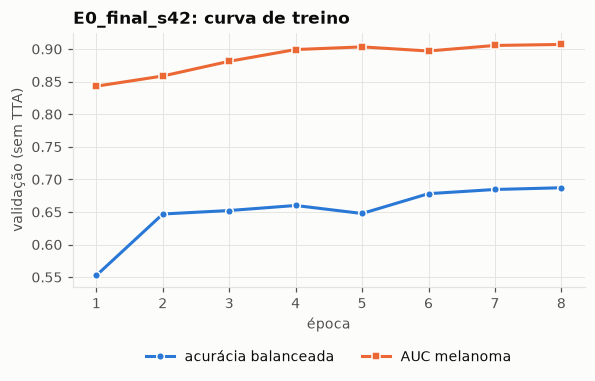

In [4]:
display(rel.tabela_finais(['E0_final_s42'], ['E0 receita']))
rel.curva('E0_final_s42'); plt.show()

### 3–4. Resultado e leitura
- Acurácia balanceada **0,696**, spec95 **0,689**, AUC melanoma 0,912 (validação, TTA 8).
- **A curva ainda subia na 8ª época**: partindo do ImageNet, 8 épocas são poucas (o Keras original
  partia de pesos já ajustados no ISIC 2019). Primeira hipótese para a busca: mais épocas.
- tau alto (1,45): treinado na distribuição natural (muitos nevos), precisa de desconto forte do prior.

## E0_busca — a mesma rede com parâmetros otimizados

### 1. Como funciona


Mesma EfficientNetV2-B0 do E0, agora com todos os parâmetros livres (inclusive resolução 224/288/384).
Separa "ganho de ajustar parâmetros" de "ganho de trocar de rede": a comparação justa de E1/E2 é contra
esta etapa, não só contra a receita.

### 2. O que foi variado

Todos os parâmetros comuns do plano (faixas abaixo), orçamento de 1,25 h + ~20 min.

In [5]:
faixas, melhores, vencedora = rel.resumo_busca('E0_busca')
faixas

Busca E0_busca: 11 tentativas {'COMPLETE': 8, 'PRUNED': 2, 'FAIL': 1} | tempo de GPU registrado: 2.0 h


,parâmetro,faixa
0,res,"224, 288, 384"
1,lr,1e-05 a 0.0005 (log)
2,wd,0.001 a 0.1 (log)
3,batch,"16, 32, 64"
4,epocas,6 a 15
5,aquecimento,0 a 2
6,perda,"ce, ce_ponderada, focal"
7,suavizacao,0 a 0.2
8,aug,"leve, media, forte"
9,mix_p,0 a 0.5


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [6]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
6,9,0.7345,0.7026,0.9172,0.9422,10.73
5,7,0.7222,0.7004,0.9075,0.9362,8.84
0,0,0.7006,0.6353,0.8899,0.9284,15.86
1,2,0.6988,0.6370,0.8899,0.9285,15.88
7,10,0.6915,0.5707,0.8773,0.9132,10.82


Configuração vencedora: {'res': 224, 'lr': 0.00038, 'wd': 0.00718, 'batch': 16, 'epocas': 8, 'aquecimento': 1, 'perda': 'ce', 'suavizacao': 0.11136, 'aug': 'leve', 'mix_p': 0.04859, 'mix_tipo': 'cutmix', 'sog': False, 'dropout': 0.43869, 'bn_congelada': True, 'meta': True, 'max_nevos': 0, 'balanceado': False, 'drop_path': 0.1534, 'cabeca_epocas': 1}


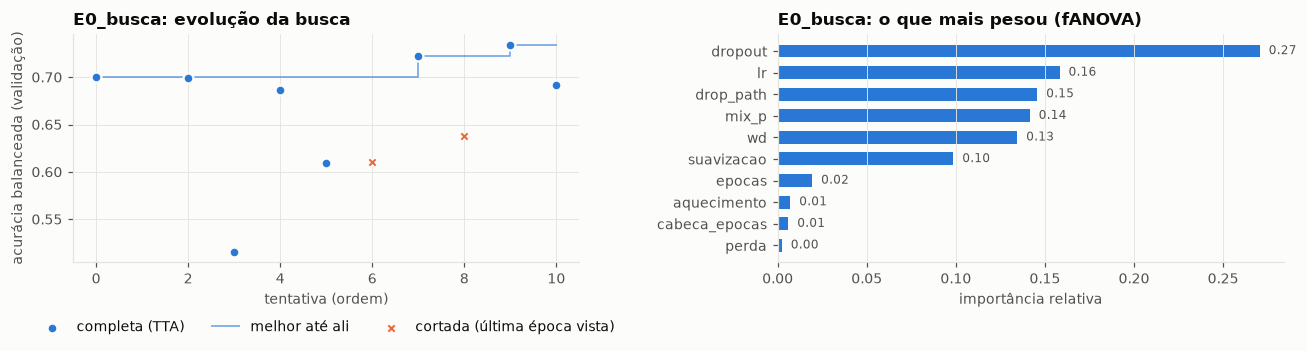

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E0_busca', axs[0])
rel.grafico_importancia('E0_busca', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- **+3,9 pontos de acurácia balanceada (0,696 → 0,7345) só com parâmetros**, mesma rede e resolução.
- lr ~4× maior (3,8e-4), suavização de rótulos 0,11, dropout/drop path maiores e **todos os nevos**
  (mais dados) explicam o ganho; lr < 3e-5 foi ruim em qualquer combinação.
- Lote 16 nas duas melhores (mais passos por época); augmentation leve e pouco mixup ganharam da forte.
- **Sem Shades of Gray** venceu — surpresa; repetiu-se na E1 e na E2.

## E1 — CNN mais forte (ConvNeXt-Tiny, até 384 px)

### 1. Como funciona


ConvNeXt-Tiny (ImageNet-22k) com resolução até 384 px. **Fraqueza atacada:** melanoma reconhecido em só
~62% — detalhes finos (rede de pigmento, bordas) se perdem a 224 px. **Hipótese:** mais resolução + CNN
moderna melhoram AUC e acerto de melanoma. A busca foi semeada com a vencedora da E0_busca a 384 px.

### 2. O que foi variado

Parâmetros comuns + resolução 224/288/384 px; 3,5 h, 16 tentativas.

In [8]:
faixas, melhores, vencedora = rel.resumo_busca('E1')
faixas

Busca E1: 16 tentativas {'COMPLETE': 9, 'PRUNED': 7} | tempo de GPU registrado: 4.7 h


,parâmetro,faixa
0,res,"224, 288, 384"
1,lr,1e-05 a 0.0005 (log)
2,wd,0.001 a 0.1 (log)
3,batch,"16, 32, 64"
4,epocas,6 a 15
5,aquecimento,0 a 2
6,perda,"ce, ce_ponderada, focal"
7,suavizacao,0 a 0.2
8,aug,"leve, media, forte"
9,mix_p,0 a 0.5


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [9]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
6,10,0.7692,0.7728,0.9326,0.9505,26.57
8,15,0.7455,0.7465,0.9210,0.9478,11.99
7,14,0.7390,0.7214,0.9240,0.9455,15.00
2,2,0.7342,0.7487,0.9309,0.9518,24.07
0,0,0.7322,0.7292,0.9248,0.9430,16.33


Configuração vencedora: {'res': 384, 'lr': 0.00026, 'wd': 0.01672, 'batch': 16, 'epocas': 9, 'aquecimento': 0, 'perda': 'focal', 'suavizacao': 0.16191, 'aug': 'leve', 'mix_p': 0.25651, 'mix_tipo': 'mixup', 'sog': False, 'dropout': 0.2656, 'bn_congelada': True, 'meta': True, 'max_nevos': 0, 'balanceado': False, 'gamma': 2.96552, 'drop_path': 0.06173, 'cabeca_epocas': 1}


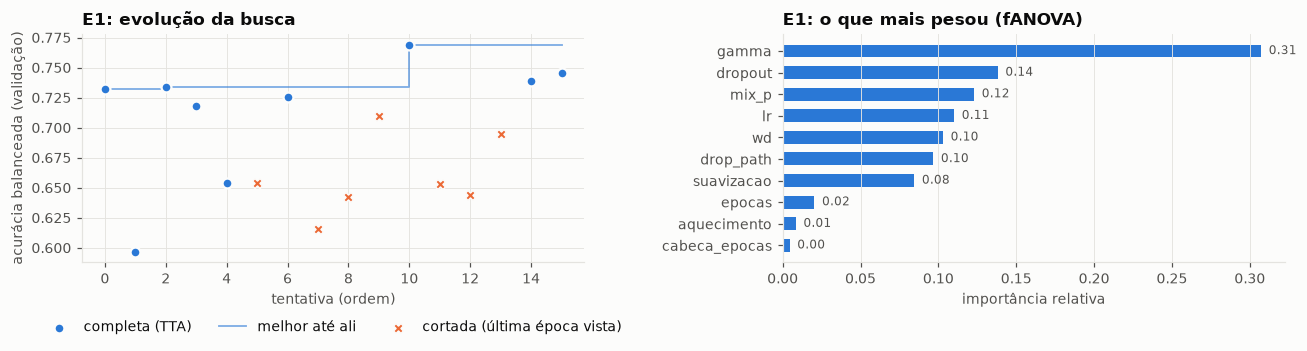

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E1', axs[0])
rel.grafico_importancia('E1', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- **Hipótese confirmada.** Acerto em melanoma 0,62 → **0,77** (+14 pontos sobre a E0_busca, 919 melanomas
  na validação); bal_acc 0,769 e spec95 0,773 (+7 pontos sobre a E0_busca: ~7% a mais dos benignos sairiam
  da fila prioritária com a mesma sensibilidade).
- **Resolução é o fator mais forte**: a tentativa 8 tinha a configuração da 2, mas a 224 px — estava em
  0,642 na 4ª época e foi cortada; a 2, a 384 px, chegou a 0,734.
- Perda **focal** com gama ~3 venceu; o gama ficou no teto da faixa (testado depois, na E1r).
- ECE alto (0,31): focal + suavização deixam as probabilidades "achatadas"; as decisões não mudam, e a
  calibração por temperatura (E5) corrige a escala.

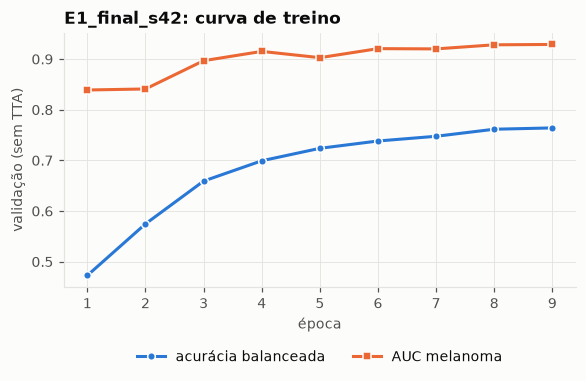

In [11]:
rel.curva('E1_final_s42'); plt.show()

## E2 — híbrido em uma rede (MaxViT-Tiny, 224 px)

### 1. Como funciona


MaxViT-Tiny: convolução e atenção em cada estágio. **Fraqueza atacada:** confusão entre ceratose benigna,
ceratose actínica e carcinoma espinocelular, que depende da forma global. **Hipótese:** a atenção capta
assimetria e forma melhor que a convolução. Fixada em 224 px por custo (4 min/época a 384 px).

### 2. O que foi variado

Parâmetros comuns + decaimento de lr por camada (0,6–1,0); semeada com a vencedora da E1.

In [12]:
faixas, melhores, vencedora = rel.resumo_busca('E2')
faixas

Busca E2: 12 tentativas {'COMPLETE': 7, 'PRUNED': 4, 'FAIL': 1} | tempo de GPU registrado: 3.5 h


,parâmetro,faixa
0,lr,1e-05 a 0.0005 (log)
1,wd,0.001 a 0.1 (log)
2,batch,"16, 32, 64"
3,epocas,6 a 15
4,aquecimento,0 a 2
5,perda,"ce, ce_ponderada, focal"
6,suavizacao,0 a 0.2
7,aug,"leve, media, forte"
8,mix_p,0 a 0.5
9,mix_tipo,"mixup, cutmix"


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [13]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
1,1,0.7490,0.7272,0.9247,0.9453,28.31
5,10,0.7462,0.7543,0.9207,0.9480,27.86
6,11,0.7451,0.7465,0.9275,0.9460,27.89
3,4,0.7324,0.6680,0.9167,0.9320,20.58
0,0,0.6926,0.6926,0.9172,0.9395,17.00


Configuração vencedora: {'lr': 0.00026, 'wd': 0.01672, 'batch': 16, 'epocas': 9, 'aquecimento': 0, 'perda': 'focal', 'suavizacao': 0.16191, 'aug': 'leve', 'mix_p': 0.25651, 'mix_tipo': 'mixup', 'sog': False, 'dropout': 0.2656, 'bn_congelada': True, 'meta': True, 'max_nevos': 0, 'balanceado': False, 'gamma': 2.96552, 'drop_path': 0.06173, 'cabeca_epocas': 1, 'layer_decay': 0.8}


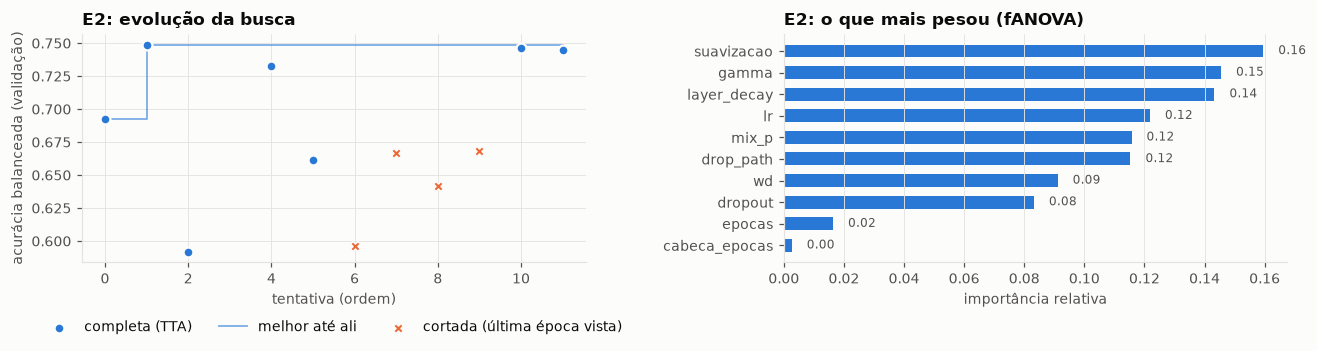

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E2', axs[0])
rel.grafico_importancia('E2', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- bal_acc 0,746–0,749: acima do B0 otimizado (0,7345) na mesma resolução, abaixo da E1 a 384 px.
- **Hipótese não confirmada**: acerta mais ceratose benigna (0,708, melhor de todos), mas a confusão
  bkl/ak/scc fica igual à do B0 (0,180 × 0,179).
- O decaimento por camada não mudou nada mensurável (0,65/0,8/0,95 → 0,746/0,749/0,745).
- Incidente: a VRAM transbordou para a RAM do sistema (épocas 10× mais lentas); corrigido com passos
  menores e teto de memória (ver diário).

## E1r — rodada extra da E1 (refino)

Busca estreitada em volta do que funcionou (sem lr baixo, sem augmentation forte, sem SoG), testando
duas hipóteses diretas: **448 px** (mais resolução ainda ajuda?) e **gama da focal acima de 3**.

In [15]:
faixas, melhores, vencedora = rel.resumo_busca('E1r')
display(melhores); print(vencedora)

Busca E1r: 6 tentativas {'FAIL': 3, 'COMPLETE': 3} | tempo de GPU registrado: 1.5 h


,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
1,2,0.7752,0.7803,0.9340,0.9522,27.15
2,3,0.7692,NaN,NaN,NaN,NaN
0,1,0.7575,0.7499,0.9308,0.9502,36.81


{'res': 384, 'lr': 0.00026, 'wd': 0.01672, 'batch': 16, 'epocas': 9, 'aquecimento': 0, 'gamma': 4.5, 'suavizacao': 0.16191, 'aug': 'leve', 'mix_p': 0.25651, 'mix_tipo': 'mixup', 'dropout': 0.2656, 'drop_path': 0.06173, 'max_nevos': 0, 'cabeca_epocas': 1}


- **448 px piorou** (0,758 × 0,769) e é ~40% mais lento: a família ConvNeXt fica em 384 px.
- Gama 4,5 deu 0,775 na busca, mas **o retreino deu 0,765**: a diferença é ruído de augmentation (o
  número de processos de carregamento mudou entre as duas rodadas). Conclusão correta: gama 3–4,5 empatam.
- Foi daqui que veio a medida de **ruído ≈ 1 ponto** usada em todo o notebook.

## E2 a 384 px — arquitetura × resolução

### 1. Como funciona


A mesma MaxViT na resolução da E1, para separar "a MaxViT é pior" de "224 px é pior". Busca estreitada
e semeada com a vencedora da E2.

### 2. O que foi variado

Espaço estreitado (faixas abaixo), 5 h, ~1 h por tentativa.

In [16]:
faixas, melhores, vencedora = rel.resumo_busca('E2_384')
faixas

Busca E2_384: 7 tentativas {'COMPLETE': 5, 'FAIL': 1, 'PRUNED': 1} | tempo de GPU registrado: 7.1 h


,parâmetro,faixa
0,lr,0.00015 a 0.0004 (log)
1,wd,0.005 a 0.05 (log)
2,batch,"16, 32"
3,epocas,6 a 12
4,aquecimento,0 a 1
5,gamma,2 a 5
6,suavizacao,0.05 a 0.2
7,aug,"leve, media"
8,mix_p,0 a 0.4
9,mix_tipo,"mixup, cutmix"


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [17]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
2,3,0.7680,0.7353,0.9355,0.9484,41.69
4,6,0.7628,0.7664,0.9219,0.9469,64.91
0,1,0.7565,0.7739,0.9280,0.9495,60.43
1,2,0.7557,0.7644,0.9375,0.9508,53.03
3,5,0.7471,0.7247,0.9173,0.9466,28.09


Configuração vencedora: {'lr': 0.00028, 'wd': 0.00818, 'batch': 16, 'epocas': 9, 'aquecimento': 1, 'gamma': 2.77535, 'suavizacao': 0.14973, 'aug': 'leve', 'mix_p': 0.22518, 'mix_tipo': 'cutmix', 'dropout': 0.14161, 'drop_path': 0.04059, 'max_nevos': 6000, 'cabeca_epocas': 1}


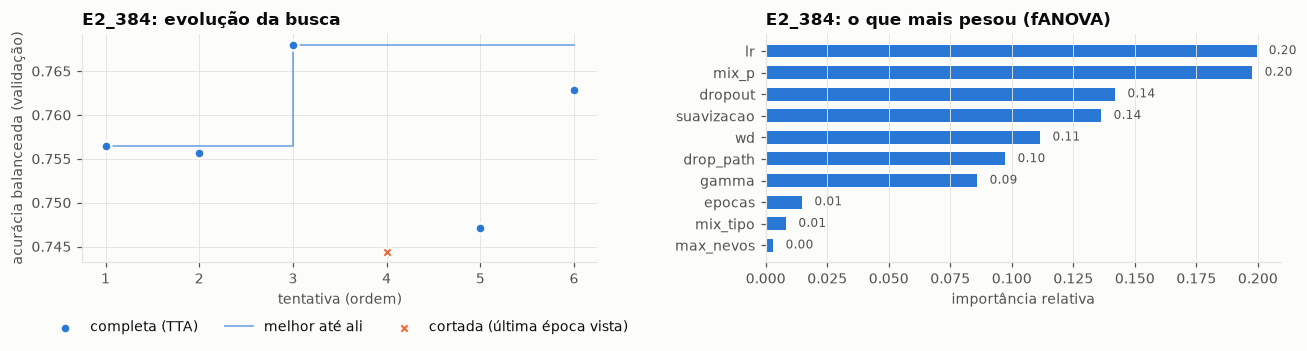

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E2_384', axs[0])
rel.grafico_importancia('E2_384', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- **Resolução explica a maior parte da distância entre E1 e E2**: na própria MaxViT, 224 → 384 px deu
  +10 pontos em melanoma e +6,5 em spec95.
- **Na mesma resolução, as arquiteturas empatam**: bal_acc 0,768 × 0,769, spec95 0,747–0,774 × 0,773.
- A hipótese da E2 segue não confirmada (confusão bkl/ak/scc 0,179); a MaxViT é melhor em carcinoma
  espinocelular, o ConvNeXt em melanoma e dermatofibroma — erram em lesões diferentes (bom para a E5).

## Teste rápido do PanDerm (antes da E4)

Vetores congelados do PanDerm (ViT-L/16, modelo de fundação de dermatologia), sem ajuste fino, com três
classificadores simples na CPU.

In [19]:
pr = rel.experimentos().query("etapa == 'PanDerm_rapido'")
pr[['familia','val_bal_acc','val_spec95','val_mel_auc','val_mal_auc','tempo_treino_min']].round(3)

,familia,val_bal_acc,val_spec95,val_mel_auc,val_mal_auc,tempo_treino_min
42,regressao_logistica,0.632,0.613,0.897,0.919,0.27
43,mlp,0.621,0.653,0.910,0.921,3.54
44,lightgbm,0.540,0.674,0.911,0.935,1.45


- **As AUCs empatam com o E0 receita** (maligno × benigno 0,935 × 0,933) em 1–4 min de CPU, sem ajuste
  fino: um modelo pronto chega perto de uma CNN treinada, a uma fração do custo, na decisão binária.
- Na classificação em 8 classes fica abaixo (0,54–0,63): os vetores separam maligno/benigno, mas
  classificadores simples erram mais nas classes raras. A E4 segue como planejada.

## E3 — fusão de dois ramos (ConvNeXt + Swin-Tiny)

### 1. Como funciona


ConvNeXt (detalhe local, partindo dos pesos da E1) e Swin-Tiny (relações entre regiões distantes) em
paralelo, mais metadados; a junção (concatenação, porta aprendida ou atenção cruzada) decide quanto
confiar em cada um. **Hipótese:** dois olhares separados se complementam mais do que misturados numa
rede (E2).

### 2. O que foi variado

Parâmetros comuns + tipo de junção, lr do ramo Swin (0,1–1× o do ConvNeXt), épocas com os ramos congelados (0–3), cabeça 256/512; 3 h.

In [20]:
faixas, melhores, vencedora = rel.resumo_busca('E3')
faixas

Busca E3: 10 tentativas {'COMPLETE': 6, 'PRUNED': 4} | tempo de GPU registrado: 5.1 h


,parâmetro,faixa
0,res,"224, 288, 384"
1,lr,1e-05 a 0.0005 (log)
2,wd,0.001 a 0.1 (log)
3,batch,"16, 32, 64"
4,epocas,6 a 15
5,aquecimento,0 a 2
6,perda,"ce, ce_ponderada, focal"
7,suavizacao,0 a 0.2
8,aug,"leve, media, forte"
9,mix_p,0 a 0.5


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [21]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
5,7,0.7669,0.7560,0.9260,0.9495,23.74
0,0,0.7572,0.7211,0.9094,0.9404,12.60
1,1,0.7534,0.7731,0.9308,0.9507,17.08
3,3,0.7474,0.7180,0.9074,0.9386,22.26
4,4,0.7465,0.7216,0.9020,0.9410,19.30


Configuração vencedora: {'res': 384, 'lr': 5e-05, 'wd': 0.08576, 'batch': 16, 'epocas': 9, 'aquecimento': 2, 'perda': 'focal', 'suavizacao': 0.18723, 'aug': 'leve', 'mix_p': 0.3075, 'mix_tipo': 'mixup', 'sog': False, 'dropout': 0.37038, 'bn_congelada': False, 'meta': True, 'max_nevos': 0, 'balanceado': True, 'gamma': 1.75379, 'drop_path': 0.23949, 'juncao': 'atencao', 'lr_vit_mult': 0.77626, 'ramos_congelados_epocas': 1, 'hidden': 256}


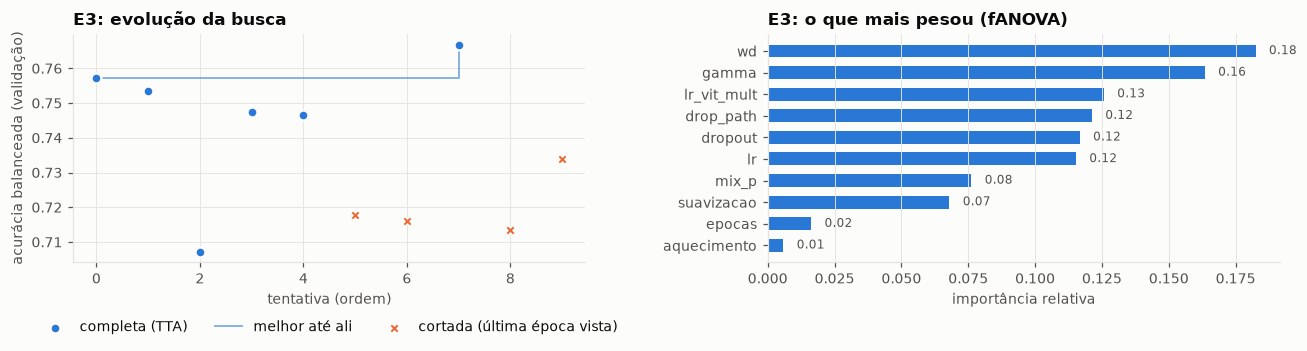

In [22]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E3', axs[0])
rel.grafico_importancia('E3', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- **A fusão não superou a E1 sozinha**: melhor 0,767 × 0,769 (empate dentro do ruído); spec95
  0,756–0,773 × 0,773. Hipótese não confirmada nesta forma: o Swin a 224 px não acrescentou informação
  que o ConvNeXt a 384 px já não tivesse.
- Como o ramo ConvNeXt já parte treinado, **lr baixo (5e-5)** funcionou melhor que o da E1 (2,6e-4).
- 384 px de novo nas melhores; junção por atenção cruzada venceu, mas com poucas tentativas por tipo.

## E4 — fusão + conhecimento de dermatologia (PanDerm)

### 1. Como funciona


Terceiro ramo na fusão da E3: o vetor congelado do PanDerm (1.024 números por imagem, sem ajuste fino).
**Fraqueza atacada:** classes raras com poucos exemplos (dermatofibroma, lesão vascular, carcinoma
espinocelular). **Hipótese:** um modelo que viu muito mais pele compensa a falta de exemplos raros. A
busca foi semeada com a vencedora da E3 + PanDerm.

### 2. O que foi variado

Os mesmos parâmetros da E3 + dropout no vetor do PanDerm (0–0,6) e vetor normalizado ou não; 3 h.

In [23]:
faixas, melhores, vencedora = rel.resumo_busca('E4')
faixas

Busca E4: 9 tentativas {'COMPLETE': 7, 'PRUNED': 2} | tempo de GPU registrado: 4.2 h


,parâmetro,faixa
0,res,"224, 288, 384"
1,lr,1e-05 a 0.0005 (log)
2,wd,0.001 a 0.1 (log)
3,batch,"16, 32, 64"
4,epocas,6 a 15
5,aquecimento,0 a 2
6,perda,"ce, ce_ponderada, focal"
7,suavizacao,0 a 0.2
8,aug,"leve, media, forte"
9,mix_p,0 a 0.5


### 3. Resultados

As 5 melhores tentativas na validação e a configuração vencedora:

In [24]:
display(melhores)
print('Configuração vencedora:', vencedora)

,tentativa,bal_acc,spec95,AUC melanoma,AUC maligno,min
1,1,0.7656,0.7557,0.9259,0.9494,25.22
3,3,0.7649,0.7334,0.9268,0.9469,18.43
6,8,0.7630,0.7451,0.9323,0.9484,25.22
5,7,0.7591,0.7652,0.9313,0.9496,33.90
0,0,0.7486,0.7007,0.9094,0.9382,25.31


Configuração vencedora: {'res': 384, 'lr': 5e-05, 'wd': 0.08576, 'batch': 16, 'epocas': 9, 'aquecimento': 2, 'perda': 'focal', 'suavizacao': 0.18723, 'aug': 'leve', 'mix_p': 0.3075, 'mix_tipo': 'mixup', 'sog': False, 'dropout': 0.37038, 'bn_congelada': False, 'meta': True, 'max_nevos': 0, 'balanceado': True, 'gamma': 1.75379, 'drop_path': 0.23949, 'juncao': 'atencao', 'lr_vit_mult': 0.77626, 'ramos_congelados_epocas': 1, 'hidden': 256, 'emb_dropout': 0.3, 'emb_norm': True}


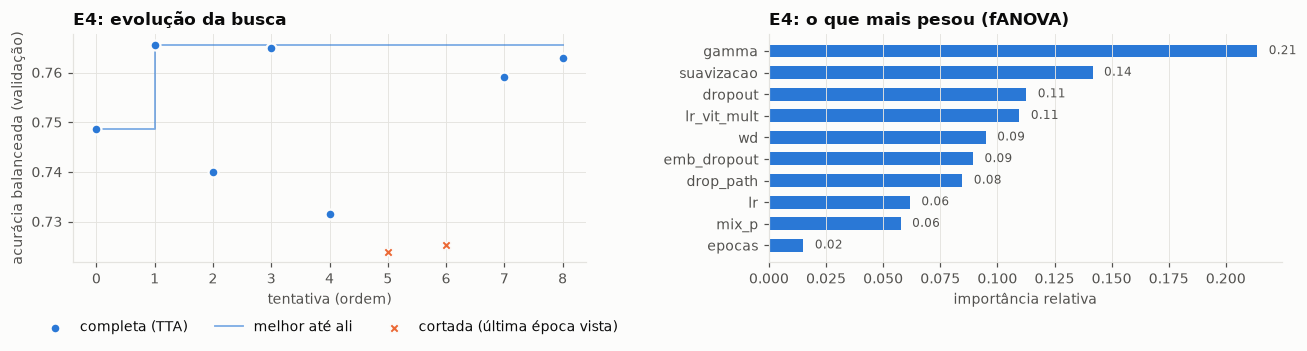

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
rel.grafico_busca('E4', axs[0])
rel.grafico_importancia('E4', axs[1])
plt.tight_layout(); plt.show()

### 4. O que funcionou, o que não e por quê


- **O PanDerm não acrescentou nada**: a vencedora (a semeada) deu 0,766 / spec95 0,756; a mesma
  configuração sem o PanDerm (E3 #7) deu 0,767 / 0,756 — idêntico. Retreino: 0,757 / 0,749.
- **Hipótese não confirmada**: os vetores congelados repetem informação que a CNN treinada já tem; o teste
  rápido já indicava que eles separam maligno/benigno bem, mas não as classes raras.
- Efeito colateral bom: as melhores tentativas tiveram calibração excelente (ECE 0,024–0,036).

## E5 — ensemble final com calibração

### 1. Como funciona
Combina as previsões de validação da melhor de cada família (E1, E2 a 384 px, E3, E4) e calibra as
probabilidades com uma temperatura. **Fraqueza atacada:** variação entre modelos e probabilidades mal
calibradas (ECE de ~0,3 em E1/E2). **Hipótese:** modelos diferentes erram em imagens diferentes. Como usa as
previsões da própria validação, é **ajustado na metade A** e **avaliado na metade B** (divisão por grupo).

### 2. O que foi variado
Todos os subconjuntos dos 4 modelos × média simples, média ponderada (pesos ótimos na metade A) e LightGBM
sobre as probabilidades; temperatura ajustada na metade A. Minutos na CPU.

In [26]:
ens = pd.read_csv('resultados/ensemble_busca.csv')
ens[['membros','metodo','bal_acc','spec95','mel_auc','mal_auc','ece','temperatura']].head(10).round(4)

,membros,metodo,bal_acc,spec95,mel_auc,mal_auc,ece,temperatura
0,E1_final_s42+E2_384_final_s42+E3_final_s42+E4_...,media,0.7752,0.7754,0.9452,0.9500,0.0555,0.4598
1,E1_final_s42+E2_384_final_s42+E3_final_s42,media,0.7742,0.7675,0.9439,0.9495,0.0502,0.4294
2,E1_final_s42+E2_384_final_s42,media,0.7696,0.7771,0.9419,0.9446,0.0530,0.3734
3,E1_final_s42,media,0.7689,0.7569,0.9291,0.9303,0.1901,0.3506
4,E1_final_s42+E2_384_final_s42+E4_final_s42,media,0.7679,0.7704,0.9457,0.9491,0.0609,0.4310
5,E1_final_s42+E2_384_final_s42+E3_final_s42,ponderada,0.7676,0.7344,0.9376,0.9478,0.0511,0.5737
6,E2_384_final_s42+E3_final_s42,ponderada,0.7676,0.7344,0.9376,0.9478,0.0511,0.5737
7,E3_final_s42,media,0.7676,0.7344,0.9376,0.9478,0.0511,0.5737
8,E1_final_s42+E3_final_s42,ponderada,0.7676,0.7344,0.9376,0.9478,0.0511,0.5737
9,E1_final_s42+E2_384_final_s42+E3_final_s42+E4_...,ponderada,0.7674,0.7395,0.9400,0.9488,0.0491,0.5663


### 3–4. Resultado e leitura (metade B da validação)
- Vencedor: **média simples dos 4 modelos + temperatura**: bal_acc 0,775, **spec95 0,775, AUC melanoma
  0,945, AUC maligno 0,950, ECE 0,056**. A E1 sozinha, na mesma metade B: 0,769 / 0,757 / 0,929 / 0,930 / 0,190.
- O ganho em bal_acc (+0,6) está dentro do ruído; **os ganhos reais são de ordenação e calibração**
  (AUC maligno +0,020, AUC melanoma +0,016, spec95 +1,8 ponto, ECE 0,19 → 0,056): exatamente o que importa
  para triagem. **Hipótese confirmada** nas métricas de triagem.
- Média simples ganhou da ponderada e do LightGBM: com metade da validação para ajustar, mais parâmetros
  não compensam.
- Achado: a decisão em 8 classes da E2 a 384 px é muito sensível ao tau (0,722 na metade B com o tau da
  metade A, 0,779 com o da validação inteira); a média do ensemble amortece essa instabilidade.

## Finalistas: 3 sementes cada

O ruído entre rodadas (~1 ponto) é do tamanho das diferenças entre os melhores modelos. Os 3 maiores
bal_acc da validação foram retreinados com as sementes 43 e 44 (mesma configuração), como manda o
protocolo: **uma diferença menor que a variação entre sementes é empate.**

,sementes,bal_acc,spec95,AUC mel,AUC mal,ECE
modelo,,,,,,
E1 ConvNeXt 384,3,0.764 ± 0.005,0.766 ± 0.006,0.934 ± 0.002,0.952 ± 0.001,0.314 ± 0.001
E2 MaxViT 384,3,0.757 ± 0.010,0.746 ± 0.004,0.932 ± 0.001,0.948 ± 0.001,0.273 ± 0.002
E3 fusão ConvNeXt+Swin,3,0.761 ± 0.003,0.753 ± 0.008,0.922 ± 0.008,0.947 ± 0.002,0.207 ± 0.021


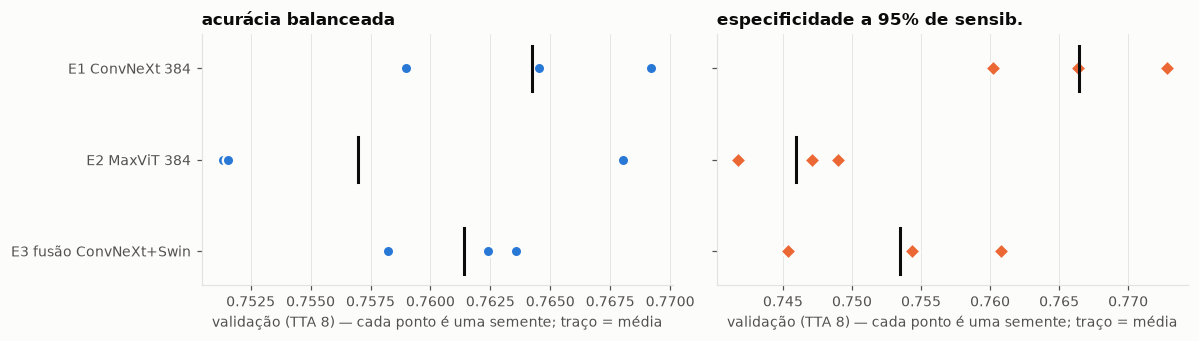

In [27]:
display(rel.tabela_sementes(["E1", "E2_384", "E3"], ["E1 ConvNeXt 384", "E2 MaxViT 384", "E3 fus\u00e3o ConvNeXt+Swin"]))
rel.grafico_sementes(["E1", "E2_384", "E3"], ["E1 ConvNeXt 384", "E2 MaxViT 384", "E3 fus\u00e3o ConvNeXt+Swin"]); plt.tight_layout(); plt.show()

- **Acurácia balanceada: empate.** E1 0,764 ± 0,005, E3 0,761 ± 0,003, E2 a 384 px 0,757 ± 0,010 — as
  médias diferem menos que o desvio entre sementes.
- **Especificidade a 95%: vantagem pequena e consistente da E1** (0,766 ± 0,006 × 0,754 ± 0,008 da E3 e
  0,746 ± 0,004 da E2 a 384 px): as três sementes da E1 ficam acima de todas as da E2 a 384 px.
- AUCs praticamente iguais (melanoma 0,922–0,934; maligno 0,947–0,952).
- Os números de uma semente só (seção de cada etapa) são um pouco otimistas: a seed 42 foi a escolhida pela
  busca. A média de 3 sementes é a estimativa honesta para levar aos testes.

## Linha de raciocínio

1. **E0 → E0_busca:** a receita estava sub-treinada (curva subindo na última época); otimizar parâmetros
   na mesma rede deu +3,9 pontos. Isso virou a régua justa para as redes novas.
2. **E0_busca → E1:** a fraqueza medida era melanoma (~62%). ConvNeXt a 384 px levou melanoma a 77% e spec95
   a 0,773 — maior ganho do projeto. A resolução, mais que a rede, explicou o salto.
3. **E1 → E2:** sobrava a confusão entre ceratoses e carcinoma espinocelular. A MaxViT não a reduziu; a
   224 px ficou atrás da E1, e a 384 px empatou com ela — a diferença era resolução, não arquitetura.
4. **E1/E2 → E3:** juntar CNN e Transformer em ramos separados não superou a CNN sozinha: o ramo Swin
   (224 px) não trouxe informação nova para um ConvNeXt já a 384 px.
5. **E3 → E4:** o PanDerm congelado separava maligno/benigno tão bem quanto o E0, mas como terceiro ramo
   não acrescentou nada: repete informação que a CNN treinada já tem.
6. **E1–E4 → E5:** como os modelos erram em lesões diferentes (MaxViT melhor em carcinoma espinocelular,
   ConvNeXt em melanoma e dermatofibroma), a média deles com calibração melhorou ordenação (AUC maligno
   0,930 → 0,950) e calibração (ECE 0,19 → 0,056) — o que importa para priorizar a fila.
7. **Finalistas:** com 3 sementes, E1, E3 e E2 a 384 px empatam em acurácia balanceada; a E1 mantém
   uma vantagem pequena em spec95.

A tabela abaixo usa uma semente por modelo (a 42); a linha do E5 é medida só na metade B da validação.

In [28]:
finais = rel.tabela_finais(["E0_final_s42", "E0_busca_final_s42", "E2_final_s42", "E2_384_final_s42", "E1_final_s42", "E1r_final_s42", "E3_final_s42", "E4_final_s42", "E5_ensemble"], ["E0 receita (B0 224)", "E0_busca (B0 224)", "E2 MaxViT 224", "E2 MaxViT 384", "E1 ConvNeXt 384", "E1r ConvNeXt 384 (refino)", "E3 fus\u00e3o ConvNeXt+Swin", "E4 fus\u00e3o + PanDerm", "E5 ensemble (metade B)"])
finais

,res,bal_acc,spec95,AUC mel,AUC mal,ECE,treino (min),ms/imagem
modelo,,,,,,,,
E0 receita (B0 224),224.0,0.6962,0.6892,0.9123,0.9333,0.0564,9.49,0.220
E0_busca (B0 224),224.0,0.7345,0.7026,0.9172,0.9422,0.0546,10.29,0.236
E2 MaxViT 224,224.0,0.7459,0.7091,0.9219,0.9426,0.3153,27.88,1.033
E2 MaxViT 384,384.0,0.7680,0.7471,0.9306,0.9481,0.2714,41.67,3.105
E1 ConvNeXt 384,384.0,0.7692,0.7728,0.9326,0.9505,0.3137,26.64,1.500
E1r ConvNeXt 384 (refino),384.0,0.7647,0.7697,0.9329,0.9512,0.3814,25.41,1.407
E3 fusão ConvNeXt+Swin,384.0,0.7636,0.7608,0.9301,0.9482,0.2287,50.38,2.156
E4 fusão + PanDerm,384.0,0.7567,0.7487,0.9317,0.9456,0.2278,53.50,2.203
E5 ensemble (metade B),NaN,0.7752,0.7754,0.9452,0.9500,0.0555,NaN,NaN


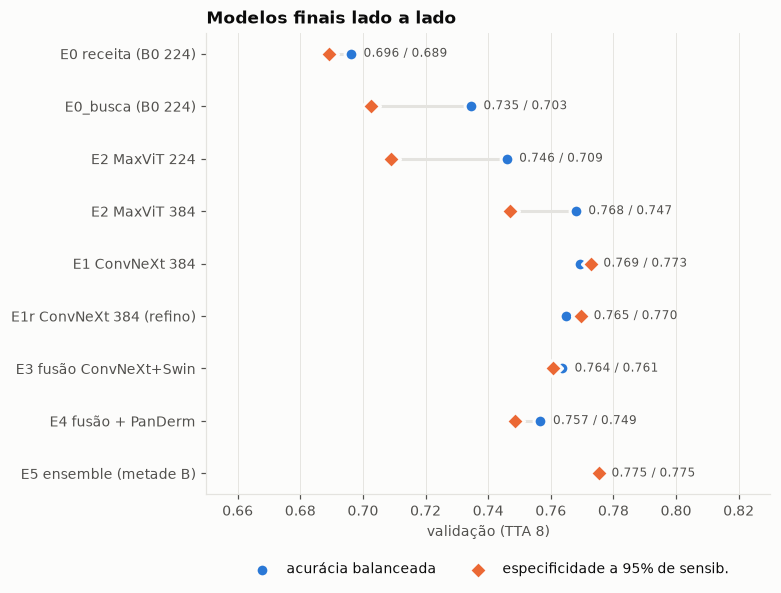

In [29]:
rel.grafico_finais(finais); plt.tight_layout(); plt.show()

,ak,bcc,bkl,df,mel,nv,scc,vasc,confusão bkl/ak/scc
E0 receita (B0 224),0.616,0.660,0.558,0.787,0.625,0.794,0.609,0.92,0.191
E0_busca (B0 224),0.627,0.766,0.564,0.872,0.615,0.833,0.639,0.96,0.179
E2 MaxViT 224,0.593,0.777,0.708,0.787,0.634,0.869,0.658,0.94,0.180
E2 MaxViT 384,0.593,0.778,0.662,0.851,0.749,0.834,0.698,0.98,0.171
E1 ConvNeXt 384,0.576,0.807,0.658,0.915,0.770,0.803,0.663,0.96,0.167
E1r ConvNeXt 384 (refino),0.588,0.823,0.660,0.851,0.753,0.854,0.668,0.92,0.168
E3 fusão ConvNeXt+Swin,0.492,0.831,0.665,0.872,0.761,0.850,0.738,0.90,0.148
E4 fusão + PanDerm,0.514,0.858,0.680,0.851,0.777,0.854,0.619,0.90,0.170


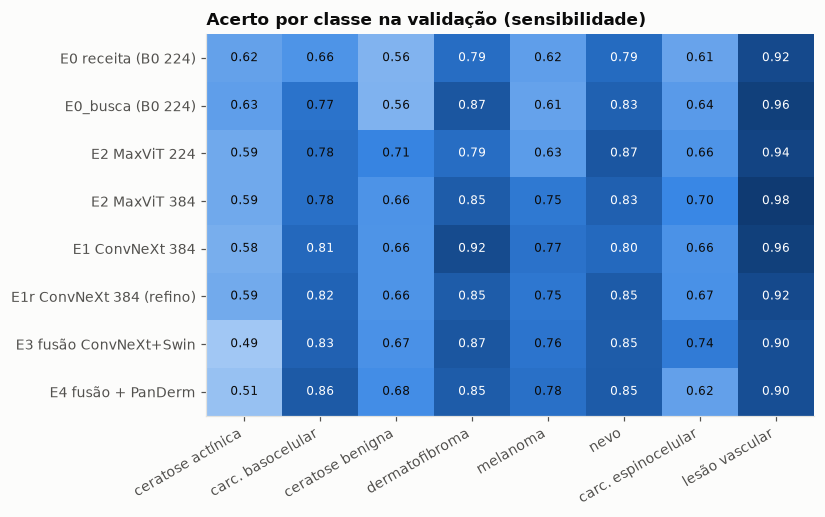

In [30]:
tab = rel.recall_por_classe(["E0_final_s42", "E0_busca_final_s42", "E2_final_s42", "E2_384_final_s42", "E1_final_s42", "E1r_final_s42", "E3_final_s42", "E4_final_s42"], ["E0 receita (B0 224)", "E0_busca (B0 224)", "E2 MaxViT 224", "E2 MaxViT 384", "E1 ConvNeXt 384", "E1r ConvNeXt 384 (refino)", "E3 fus\u00e3o ConvNeXt+Swin", "E4 fus\u00e3o + PanDerm"])
display(tab)
rel.heatmap_recall(tab); plt.tight_layout(); plt.show()

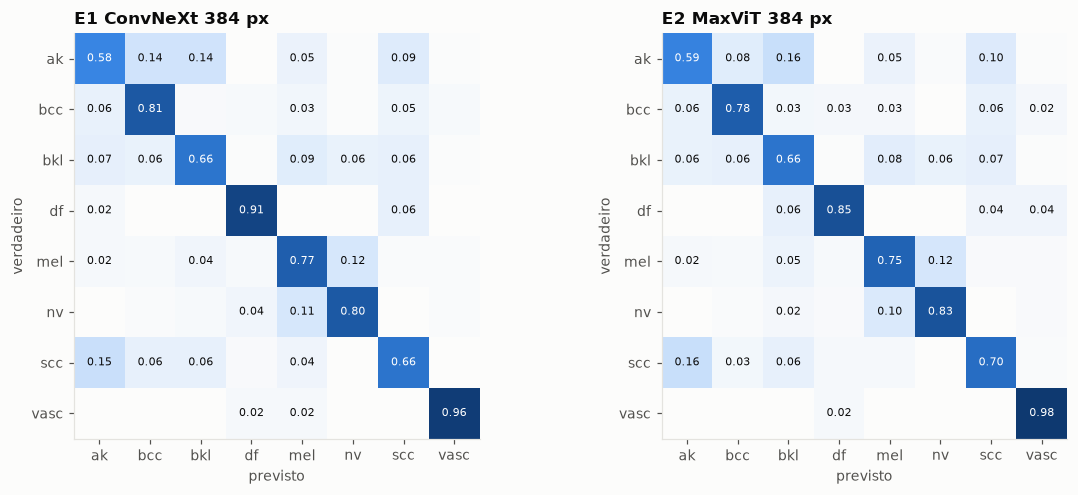

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
rel.matriz_confusao('E1_final_s42', 'E1 ConvNeXt 384 px', axs[0])
rel.matriz_confusao('E2_384_final_s42', 'E2 MaxViT 384 px', axs[1])
plt.tight_layout(); plt.show()

### Testes (T1 = ISIC 2018, comparação com dermatologistas; T2 = metade do teste ISIC 2019)

*Ainda não abertos.* Serão rodados uma única vez nos finalistas (`python -m dermato.testar`), com
bootstrap pareado contra o E0 (2.000 amostras) e a comparação com os dermatologistas de Tschandl et al.
(2020). Esta seção mostrará a diferença entre validação e teste.

### Conclusão (validação; testes ainda fechados)

- O que mais rendeu: **parâmetros** (+3,9 pontos no B0) e **resolução 384 px** (+10 pontos em melanoma),
  não a troca de arquitetura: ConvNeXt e MaxViT empatam na mesma resolução; a fusão com Transformer (E3) e
  o PanDerm (E4) não somaram.
- Melhor modelo individual: **E1 (ConvNeXt-Tiny 384 px)** — 3 sementes: bal_acc 0,764 ± 0,005, spec95
  0,766 ± 0,006, AUC melanoma 0,934 — empatado em acurácia com E3 e E2 a 384 px, um pouco à frente em spec95.
- Melhor sistema para triagem: **E5 (média dos 4 + temperatura)** — melhor ordenação (AUC maligno 0,950) e
  probabilidades calibradas (ECE 0,056).
- Ceratose actínica continua a classe mais difícil (0,57–0,63) em todas as etapas.
- Candidatos para abrir os testes: **E0 (régua), E1 (3 sementes) e E5**.